# 01a — Training FCOS (ResNet50 + FPN)

Notebook fine-tuning FCOS untuk klasifikasi objek `awake` dan `drowsy` berdasarkan PRD v1.4.

**Konfigurasi utama:** input 640×480, batch size efektif 8, AdamW (LR 0.0001), maksimum 70 epoch, AMP, pemilihan checkpoint berdasarkan validation mAP@0.5, early stopping patience 10, checkpoint setiap epoch, dan resume training.

> Jalankan pada Kaggle dengan GPU T4 dan Internet **On**. Sesuaikan `CFG["DATASET_ROOT"]` dengan slug dataset pada panel Input. Dataset harus memiliki `train/` dan `valid/`, masing-masing berisi `annotation.coco.json` dan `images/awake/`, `images/drowsy/`.

## 1. Setup dan konfigurasi

Sel ini menjadi blok setup utama notebook. Catat versi setup, hash konfigurasi, seed, versi library, dan GPU agar eksperimen dapat direproduksi.

In [1]:
import os, json, math, time, random, hashlib, platform, copy, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import pandas as pd
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.transforms import functional as TF
from torchvision.models.detection import fcos_resnet50_fpn
from torchvision.models.detection import FCOS_ResNet50_FPN_Weights

SETUP_VERSION = "FCOS-TRAIN-1.0.0"

CFG = {
    # Ganti slug ini sesuai nama dataset pada /kaggle/input
    "DATASET_ROOT": "/kaggle/input/datasets/ahmadrizalmustofa/dataset-nthu-ddd-balance/dataset_balanced",
    "TRAIN_DIR": "train",
    "VALID_DIR": "valid",
    "ANNOTATION_NAME": "annotation.coco.json",

    "IMAGE_WIDTH": 640,
    "IMAGE_HEIGHT": 480,
    "BATCH_SIZE": 8,                 # batch efektif
    "MICRO_BATCH_SIZE": 8,           # ubah menjadi 4 jika OOM
    "GRAD_ACCUM_STEPS": 1,           # jika micro batch 4: set 2
    "LEARNING_RATE": 1e-4,
    "WEIGHT_DECAY": 1e-4,
    "MAX_EPOCHS": 70,
    "EARLY_STOPPING_PATIENCE": 10,
    "NUM_WORKERS": 2,
    "SEED": 42,
    "AMP": True,
    "CONF_THRESHOLD": 0.5,
    "MAP_IOU_THRESHOLD": 0.5,
    "MAP_SCORE_THRESHOLD": 0.05,
    "CHECKPOINT_DIR": "/kaggle/working/checkpoints_fcos",
    "OUTPUT_DIR": "/kaggle/working/fcos_training_outputs",
    # Isi path checkpoint .pth untuk melanjutkan training; None untuk mulai baru
    "RESUME_CHECKPOINT": None,
    # True = gunakan bobot deteksi COCO Torchvision, lalu ganti classification layer.
    # Internet Kaggle harus aktif saat pertama kali mengunduh bobot.
    "USE_COCO_PRETRAINED": True,
}

assert CFG["BATCH_SIZE"] == CFG["MICRO_BATCH_SIZE"] * CFG["GRAD_ACCUM_STEPS"], \
    "Batch efektif harus tetap 8 (micro batch × accumulation)."
assert CFG["IMAGE_WIDTH"] == 640
assert CFG["IMAGE_HEIGHT"] == 480

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

set_seed(CFG["SEED"])
os.makedirs(CFG["CHECKPOINT_DIR"], exist_ok=True)
os.makedirs(CFG["OUTPUT_DIR"], exist_ok=True)

cfg_payload = json.dumps(CFG, sort_keys=True, default=str)
CFG_HASH = hashlib.sha256(cfg_payload.encode()).hexdigest()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("SETUP_VERSION:", SETUP_VERSION)
print("CFG SHA256:", CFG_HASH)
print("Seed:", CFG["SEED"])
print("Device:", DEVICE, "| GPU:", GPU_NAME)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__, "| Torchvision:", torchvision.__version__)
print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

SETUP_VERSION: FCOS-TRAIN-1.0.0
CFG SHA256: c435a9e6070b29e19970f0e73200c3d847126881410ace2eb18d1fbbfc02ad2a
Seed: 42
Device: cuda | GPU: Tesla T4
Python: 3.13.16
PyTorch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130
Pandas: 2.3.3 | NumPy: 2.1.3


## 2. Verifikasi path dataset

Pastikan direktori train dan valid serta file anotasi ditemukan sebelum membuat DataLoader.

In [2]:
ROOT = Path(CFG["DATASET_ROOT"])
TRAIN_ROOT = ROOT / CFG["TRAIN_DIR"]
VALID_ROOT = ROOT / CFG["VALID_DIR"]

def split_paths(split_root):
    return {
        "images": split_root / "images",
        "annotation": split_root / CFG["ANNOTATION_NAME"],
    }

TRAIN_PATHS = split_paths(TRAIN_ROOT)
VALID_PATHS = split_paths(VALID_ROOT)

for split_name, paths in [("TRAIN", TRAIN_PATHS), ("VALID", VALID_PATHS)]:
    print(f"\\n{split_name}")
    for key, path in paths.items():
        print(f"{key}: {path} | exists={path.exists()}")
        if not path.exists():
            raise FileNotFoundError(f"{split_name} {key} tidak ditemukan: {path}")

for split_name, images_dir in [("TRAIN", TRAIN_PATHS["images"]), ("VALID", VALID_PATHS["images"])]:
    for cls in ("awake", "drowsy"):
        p = images_dir / cls
        if not p.is_dir():
            raise FileNotFoundError(f"Subfolder kelas tidak ditemukan: {p}")

\nTRAIN
images: /kaggle/input/datasets/ahmadrizalmustofa/dataset-nthu-ddd-balance/dataset_balanced/train/images | exists=True
annotation: /kaggle/input/datasets/ahmadrizalmustofa/dataset-nthu-ddd-balance/dataset_balanced/train/annotation.coco.json | exists=True
\nVALID
images: /kaggle/input/datasets/ahmadrizalmustofa/dataset-nthu-ddd-balance/dataset_balanced/valid/images | exists=True
annotation: /kaggle/input/datasets/ahmadrizalmustofa/dataset-nthu-ddd-balance/dataset_balanced/valid/annotation.coco.json | exists=True


## 3. Dataset COCO dan transformasi 640×480

Label kelas diambil dari `category_id` anotasi COCO, bukan nama folder. Label Torchvision: `0` background, `1` awake, `2` drowsy. File gambar diindeks sekali menggunakan `os.walk`; nama file ganda atau file yang tidak ditemukan akan menghentikan proses dengan error.

Transformasi menggunakan resize langsung ke 640×640 dan skala bounding box yang sama. Ini mengikuti konfigurasi resolusi pada PRD.

In [3]:
CLASS_NAME_TO_LABEL = {"awake": 1, "drowsy": 2}
VALID_IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def build_image_index(images_dir):
    index = {}
    duplicates = []
    for current_root, _, files in os.walk(images_dir):
        for filename in files:
            if Path(filename).suffix.lower() not in VALID_IMAGE_EXTS:
                continue
            full_path = str(Path(current_root) / filename)
            if filename in index:
                duplicates.append((filename, index[filename], full_path))
            else:
                index[filename] = full_path
    if duplicates:
        sample = duplicates[:10]
        raise ValueError(f"Nama file gambar ganda ditemukan dalam split: {sample}")
    return index

class COCODrowsinessDataset(Dataset):
    def __init__(self, images_dir, annotation_file, image_width=640, image_height=480):
        self.images_dir = Path(images_dir)
        self.annotation_file = Path(annotation_file)

        self.image_width = int(image_width)
        self.image_height = int(image_height)

        with open(self.annotation_file, "r", encoding="utf-8") as f:
            self.coco = json.load(f)

        self.image_index = build_image_index(self.images_dir)
        self.categories = {
            int(cat["id"]): str(cat["name"]).strip().lower()
            for cat in self.coco.get("categories", [])
        }
        self.cat_id_to_label = {}
        for cat_id, cat_name in self.categories.items():
            if cat_name in CLASS_NAME_TO_LABEL:
                self.cat_id_to_label[cat_id] = CLASS_NAME_TO_LABEL[cat_name]

        if set(self.cat_id_to_label.values()) != {1, 2}:
            raise ValueError(
                "Kategori COCO harus memuat awake dan drowsy. "
                f"Kategori terbaca: {self.categories}"
            )

        self.images = self.coco.get("images", [])
        self.annotations_by_image = defaultdict(list)
        for ann in self.coco.get("annotations", []):
            self.annotations_by_image[int(ann["image_id"])].append(ann)

        self.resolved_paths = {}
        missing = []
        for image_info in self.images:
            image_id = int(image_info["id"])
            file_name = str(image_info["file_name"])
            basename = Path(file_name).name
            resolved = self.image_index.get(basename)
            if resolved is None:
                missing.append(file_name)
            else:
                self.resolved_paths[image_id] = resolved
        if missing:
            raise FileNotFoundError(
                f"{len(missing)} file gambar dari anotasi tidak ditemukan. "
                f"Contoh: {missing[:10]}"
            )

        self.images = sorted(self.images, key=lambda x: int(x["id"]))
        print(
            f"Loaded {len(self.images)} images | "
            f"{len(self.annotations_by_image)} image IDs with annotations | "
            f"{len(self.image_index)} indexed image files"
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        info = self.images[idx]
        image_id = int(info["id"])
        image_path = self.resolved_paths[image_id]

        image = Image.open(image_path).convert("RGB")
        orig_w, orig_h = image.size
        target_w = self.image_width
        target_h = self.image_height

        image = image.resize((target_w, target_h),Image.Resampling.BILINEAR)
        image = TF.to_tensor(image)  # float [0,1], model torchvision melakukan normalisasi internal

        boxes, labels, areas, iscrowd = [], [], [], []
        sx = target_w / orig_w
        sy = target_h / orig_h

        for ann in self.annotations_by_image.get(image_id, []):
            cat_id = int(ann["category_id"])
            if cat_id not in self.cat_id_to_label:
                continue
            x, y, w, h = map(float, ann["bbox"])
            x1, y1 = x * sx, y * sy
            x2, y2 = (x + w) * sx, (y + h) * sy
            x1 = min(max(x1, 0.0), target_w)
            y1 = min(max(y1, 0.0), target_h)
            x2 = min(max(x2, 0.0), target_w)
            y2 = min(max(y2, 0.0), target_h)
            if x2 <= x1 or y2 <= y1:
                continue
            boxes.append([x1, y1, x2, y2])
            labels.append(self.cat_id_to_label[cat_id])
            areas.append((x2 - x1) * (y2 - y1))
            iscrowd.append(int(ann.get("iscrowd", 0)))

        target = {
            "boxes": torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
            "labels": torch.as_tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([image_id], dtype=torch.int64),
            "area": torch.as_tensor(areas, dtype=torch.float32),
            "iscrowd": torch.as_tensor(iscrowd, dtype=torch.int64),
        }
        return image, target

def collate_fn(batch):
    return tuple(zip(*batch))

train_dataset = COCODrowsinessDataset(
    TRAIN_PATHS["images"],
    TRAIN_PATHS["annotation"],
    CFG["IMAGE_WIDTH"],
    CFG["IMAGE_HEIGHT"]
)

valid_dataset = COCODrowsinessDataset(
    VALID_PATHS["images"],
    VALID_PATHS["annotation"],
    CFG["IMAGE_WIDTH"],
    CFG["IMAGE_HEIGHT"]
)

train_loader = DataLoader(
    train_dataset, batch_size=CFG["MICRO_BATCH_SIZE"], shuffle=True,
    num_workers=CFG["NUM_WORKERS"], pin_memory=(DEVICE.type == "cuda"),
    collate_fn=collate_fn, drop_last=False,
    persistent_workers=(CFG["NUM_WORKERS"] > 0)
)
valid_loader = DataLoader(
    valid_dataset, batch_size=CFG["MICRO_BATCH_SIZE"], shuffle=False,
    num_workers=CFG["NUM_WORKERS"], pin_memory=(DEVICE.type == "cuda"),
    collate_fn=collate_fn, drop_last=False,
    persistent_workers=(CFG["NUM_WORKERS"] > 0)
)
print("Train images:", len(train_dataset), "| Valid images:", len(valid_dataset))

Loaded 14000 images | 14000 image IDs with annotations | 14000 indexed image files
Loaded 1750 images | 1750 image IDs with annotations | 1750 indexed image files
Train images: 14000 | Valid images: 1750


## 4. Pemeriksaan sampel dan bounding box

Visualisasikan beberapa citra hasil resize beserta bounding box dan label untuk memastikan konversi koordinat COCO benar.

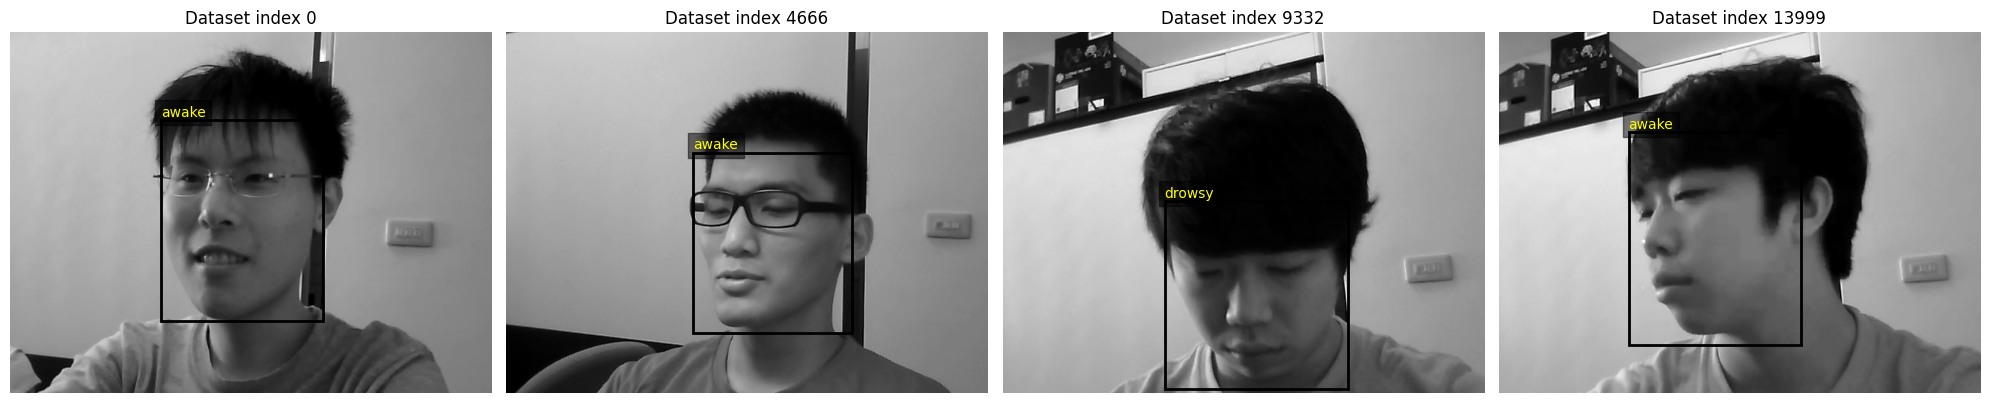

In [4]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

LABEL_TO_NAME = {1: "awake", 2: "drowsy"}

def show_dataset_samples(dataset, n=4):
    n = min(n, len(dataset))
    indices = np.linspace(0, len(dataset)-1, n, dtype=int)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]
    for ax, idx in zip(axes, indices):
        image, target = dataset[int(idx)]
        ax.imshow(image.permute(1, 2, 0).numpy())
        for box, label in zip(target["boxes"], target["labels"]):
            x1, y1, x2, y2 = box.tolist()
            ax.add_patch(patches.Rectangle(
                (x1, y1), x2-x1, y2-y1, fill=False, linewidth=2
            ))
            ax.text(x1, max(0, y1-5), LABEL_TO_NAME[int(label)], color="yellow",
                    fontsize=10, bbox=dict(facecolor="black", alpha=.5))
        ax.set_title(f"Dataset index {idx}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_dataset_samples(train_dataset, n=4)

## 5. Konstruksi model FCOS ResNet50 + FPN

Model menggunakan bobot deteksi COCO `fcos_resnet50_fpn` dari Torchvision. Classification output layer diganti menjadi 3 label (background + 2 kelas), sementara bobot pretrained lain dipertahankan. Bila `USE_COCO_PRETRAINED=False`, model memakai backbone ImageNet pretrained jika tersedia.

In [5]:
def build_fcos_model(num_classes=3, use_coco_pretrained=True):
    if use_coco_pretrained:
        weights = FCOS_ResNet50_FPN_Weights.DEFAULT
        model = fcos_resnet50_fpn(weights=weights)
        cls_head = model.head.classification_head
        old_conv = cls_head.cls_logits
        new_conv = nn.Conv2d(
            in_channels=old_conv.in_channels,
            out_channels=cls_head.num_anchors * num_classes,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding
        )
        nn.init.normal_(new_conv.weight, std=0.01)
        nn.init.constant_(new_conv.bias, -math.log((1 - 0.01) / 0.01))
        cls_head.cls_logits = new_conv
        cls_head.num_classes = num_classes
        model.num_classes = num_classes
    else:
        from torchvision.models import ResNet50_Weights
        model = fcos_resnet50_fpn(
            weights=None,
            weights_backbone=ResNet50_Weights.IMAGENET1K_V2,
            num_classes=num_classes
        )
    return model

model = build_fcos_model(
    num_classes=3,
    use_coco_pretrained=CFG["USE_COCO_PRETRAINED"]
)

# Konfigurasi ukuran input internal FCOS
model.transform.min_size = (480,)
model.transform.max_size = 640

model = model.to(DEVICE)


optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=CFG["LEARNING_RATE"],
    weight_decay=CFG["WEIGHT_DECAY"]
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

amp_enabled = bool(CFG["AMP"] and DEVICE.type == "cuda")
try:
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

print(model.__class__.__name__)
print("AMP enabled:", amp_enabled)

Downloading: "https://download.pytorch.org/models/fcos_resnet50_fpn_coco-99b0c9b7.pth" to /root/.cache/torch/hub/checkpoints/fcos_resnet50_fpn_coco-99b0c9b7.pth


100%|██████████| 124M/124M [00:01<00:00, 88.1MB/s]


FCOS
AMP enabled: True


## 6. Evaluasi validation mAP@0.5

mAP dihitung per kelas dengan IoU 0.5 dan score floor 0.05, kemudian dirata-ratakan untuk kelas awake dan drowsy. Precision dan recall tambahan dihitung pada confidence threshold 0.5. Evaluasi tidak menggunakan augmentasi.

In [6]:
def box_iou_one_to_many(box, boxes):
    if boxes.numel() == 0:
        return torch.zeros((0,), dtype=torch.float32)
    xx1 = torch.maximum(box[0], boxes[:, 0])
    yy1 = torch.maximum(box[1], boxes[:, 1])
    xx2 = torch.minimum(box[2], boxes[:, 2])
    yy2 = torch.minimum(box[3], boxes[:, 3])
    inter = (xx2-xx1).clamp(min=0) * (yy2-yy1).clamp(min=0)
    area1 = (box[2]-box[0]).clamp(min=0) * (box[3]-box[1]).clamp(min=0)
    area2 = (boxes[:,2]-boxes[:,0]).clamp(min=0) * (boxes[:,3]-boxes[:,1]).clamp(min=0)
    return inter / (area1 + area2 - inter).clamp(min=1e-8)

@torch.no_grad()
def collect_predictions(model, loader, score_floor=0.05):
    model.eval()
    records = []
    for images, targets in loader:
        images_device = [img.to(DEVICE, non_blocking=True) for img in images]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
            outputs = model(images_device)
        for target, output in zip(targets, outputs):
            keep = output["scores"].detach().cpu() >= score_floor
            records.append({
                "target": {k: v.detach().cpu() for k, v in target.items()},
                "pred": {
                    "boxes": output["boxes"].detach().cpu()[keep],
                    "labels": output["labels"].detach().cpu()[keep],
                    "scores": output["scores"].detach().cpu()[keep],
                }
            })
    return records

def compute_detection_metrics(records, iou_threshold=0.5, conf_threshold=0.5):
    per_class = {}
    total_tp_conf = total_fp_conf = total_fn_conf = 0

    for class_id, class_name in LABEL_TO_NAME.items():
        gt_by_image = {}
        n_gt = 0
        detections = []
        for image_idx, rec in enumerate(records):
            gt_mask = rec["target"]["labels"] == class_id
            gt_boxes = rec["target"]["boxes"][gt_mask]
            gt_by_image[image_idx] = {
                "boxes": gt_boxes,
                "matched": torch.zeros(len(gt_boxes), dtype=torch.bool)
            }
            n_gt += len(gt_boxes)

            pred_mask = (rec["pred"]["labels"] == class_id)
            for box, score in zip(rec["pred"]["boxes"][pred_mask], rec["pred"]["scores"][pred_mask]):
                detections.append((float(score), image_idx, box))

        detections.sort(key=lambda x: x[0], reverse=True)
        tp, fp = [], []
        for score, image_idx, box in detections:
            gt = gt_by_image[image_idx]
            ious = box_iou_one_to_many(box, gt["boxes"])
            if len(ious) > 0:
                best_iou, best_idx = ious.max(dim=0)
            else:
                best_iou, best_idx = torch.tensor(0.), torch.tensor(-1)
            if float(best_iou) >= iou_threshold and not bool(gt["matched"][int(best_idx)]):
                tp.append(1); fp.append(0)
                gt["matched"][int(best_idx)] = True
            else:
                tp.append(0); fp.append(1)

        if n_gt == 0:
            ap = float("nan")
        elif len(tp) == 0:
            ap = 0.0
        else:
            tp_cum = np.cumsum(tp)
            fp_cum = np.cumsum(fp)
            recalls = tp_cum / max(n_gt, 1)
            precisions = tp_cum / np.maximum(tp_cum + fp_cum, 1e-12)
            mrec = np.concatenate(([0.], recalls, [1.]))
            mpre = np.concatenate(([0.], precisions, [0.]))
            for i in range(len(mpre)-2, -1, -1):
                mpre[i] = max(mpre[i], mpre[i+1])
            change = np.where(mrec[1:] != mrec[:-1])[0]
            ap = float(np.sum((mrec[change+1] - mrec[change]) * mpre[change+1]))

        # Precision/recall at fixed confidence 0.5
        matched = {i: torch.zeros(len(v["boxes"]), dtype=torch.bool) for i, v in gt_by_image.items()}
        tp50 = fp50 = 0
        for score, image_idx, box in detections:
            if score < conf_threshold:
                continue
            gt_boxes = gt_by_image[image_idx]["boxes"]
            ious = box_iou_one_to_many(box, gt_boxes)
            if len(ious) and float(ious.max()) >= iou_threshold:
                best_idx = int(ious.argmax())
                if not matched[image_idx][best_idx]:
                    matched[image_idx][best_idx] = True
                    tp50 += 1
                else:
                    fp50 += 1
            else:
                fp50 += 1
        fn50 = n_gt - tp50
        precision = tp50 / max(tp50 + fp50, 1)
        recall = tp50 / max(tp50 + fn50, 1)
        total_tp_conf += tp50; total_fp_conf += fp50; total_fn_conf += fn50

        per_class[class_name] = {
            "AP50": ap, "GT": n_gt,
            "Precision@0.5": precision, "Recall@0.5": recall,
        }

    valid_aps = [v["AP50"] for v in per_class.values() if not np.isnan(v["AP50"])]
    map50 = float(np.mean(valid_aps)) if valid_aps else 0.0
    precision_all = total_tp_conf / max(total_tp_conf + total_fp_conf, 1)
    recall_all = total_tp_conf / max(total_tp_conf + total_fn_conf, 1)
    return {
        "mAP@0.5": map50,
        "Precision@0.5": precision_all,
        "Recall@0.5": recall_all,
        "per_class": per_class,
        "TP@0.5": total_tp_conf,
        "FP@0.5": total_fp_conf,
        "FN@0.5": total_fn_conf,
    }

@torch.no_grad()
def calculate_validation_loss(model, loader):
    # Torchvision detection models return loss dict in train() mode.
    # Parameters are not updated; gradients are disabled.
    model.train()
    losses = []
    for images, targets in loader:
        images = [img.to(DEVICE, non_blocking=True) for img in images]
        targets = [{k: v.to(DEVICE, non_blocking=True) for k, v in t.items()} for t in targets]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
            loss_dict = model(images, targets)
            loss = sum(loss for loss in loss_dict.values())
        losses.append(float(loss.detach().cpu()))
    model.eval()
    return float(np.mean(losses)) if losses else float("nan")

@torch.no_grad()
def evaluate_map(model, loader):
    records = collect_predictions(model, loader, CFG["MAP_SCORE_THRESHOLD"])
    return compute_detection_metrics(
        records, CFG["MAP_IOU_THRESHOLD"], CFG["CONF_THRESHOLD"]
    )

## 7. Checkpoint, resume, dan loop training

Checkpoint disimpan setiap epoch. `fcos_last.pth` digunakan untuk resume; `fcos_best.pth` dipilih berdasarkan mAP@0.5 validasi tertinggi. Early stopping menggunakan patience 10 epoch. Jika sesi Kaggle terputus, tambahkan `fcos_last.pth` sebagai input dan isi `RESUME_CHECKPOINT`.

In [7]:
BEST_PATH = os.path.join(CFG["OUTPUT_DIR"], "fcos_best.pth")
LAST_PATH = os.path.join(CFG["OUTPUT_DIR"], "fcos_last.pth")
HISTORY_CSV = os.path.join(CFG["OUTPUT_DIR"], "fcos_training_log.csv")
HISTORY_JSON = os.path.join(CFG["OUTPUT_DIR"], "fcos_training_log.json")

history = []
start_epoch = 0
best_map = -1.0
epochs_without_improvement = 0

def save_checkpoint(path, epoch, best_map, history, epochs_without_improvement):
    payload = {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "epoch": epoch,
        "best_map": best_map,
        "history": history,
        "epochs_without_improvement": epochs_without_improvement,
        "cfg": CFG,
        "cfg_hash": CFG_HASH,
        "setup_version": SETUP_VERSION,
        "seed": CFG["SEED"],
        "gpu_name": GPU_NAME,
    }
    torch.save(payload, path)

resume_path = CFG["RESUME_CHECKPOINT"]
if resume_path:
    if not os.path.isfile(resume_path):
        raise FileNotFoundError(f"Resume checkpoint tidak ditemukan: {resume_path}")
    ckpt = torch.load(resume_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])
    if "scheduler_state_dict" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
    if "scaler_state_dict" in ckpt:
        scaler.load_state_dict(ckpt["scaler_state_dict"])
    start_epoch = int(ckpt["epoch"])
    best_map = float(ckpt.get("best_map", -1.0))
    history = ckpt.get("history", [])
    epochs_without_improvement = int(ckpt.get("epochs_without_improvement", 0))
    print(f"Resumed from epoch {start_epoch}; best mAP={best_map:.4f}")
else:
    print("Training baru dimulai.")

def train_one_epoch(epoch):
    model.train()
    running_loss = 0.0
    optimizer.zero_grad(set_to_none=True)
    num_batches = len(train_loader)
    t0 = time.time()

    for step, (images, targets) in enumerate(train_loader, start=1):
        images = [img.to(DEVICE, non_blocking=True) for img in images]
        targets = [{k: v.to(DEVICE, non_blocking=True) for k, v in t.items()} for t in targets]

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp_enabled):
            loss_dict = model(images, targets)
            loss = sum(v for v in loss_dict.values())
            scaled_loss = loss / CFG["GRAD_ACCUM_STEPS"]

        if not torch.isfinite(loss):
            raise RuntimeError(f"Loss tidak finite pada epoch {epoch}, batch {step}: {loss.item()}")

        scaler.scale(scaled_loss).backward()

        if step % CFG["GRAD_ACCUM_STEPS"] == 0 or step == num_batches:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += float(loss.detach().cpu())
        if step % 50 == 0 or step == num_batches:
            print(f"Epoch {epoch} [{step}/{num_batches}] loss={loss.item():.4f}")

    return running_loss / max(num_batches, 1), time.time() - t0

training_start = time.time()
for epoch in range(start_epoch + 1, CFG["MAX_EPOCHS"] + 1):
    epoch_start = time.time()
    train_loss, train_seconds = train_one_epoch(epoch)
    val_loss = calculate_validation_loss(model, valid_loader)
    val_metrics = evaluate_map(model, valid_loader)
    val_map = val_metrics["mAP@0.5"]
    scheduler.step(val_map)

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "valid_loss": val_loss,
        "valid_mAP50": val_map,
        "valid_precision": val_metrics["Precision@0.5"],
        "valid_recall": val_metrics["Recall@0.5"],
        "learning_rate": optimizer.param_groups[0]["lr"],
        "train_time_seconds": train_seconds,
        "epoch_time_seconds": time.time() - epoch_start,
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_CSV, index=False)
    with open(HISTORY_JSON, "w") as f:
        json.dump(history, f, indent=2)

    improved = val_map > best_map
    if improved:
        best_map = val_map
        epochs_without_improvement = 0
        save_checkpoint(BEST_PATH, epoch, best_map, history, epochs_without_improvement)
        print(f"Saved BEST checkpoint: mAP@0.5={best_map:.4f}")
    else:
        epochs_without_improvement += 1

    save_checkpoint(LAST_PATH, epoch, best_map, history, epochs_without_improvement)
    print(
        f"Epoch {epoch}/{CFG['MAX_EPOCHS']} | "
        f"train_loss={train_loss:.4f} | valid_loss={val_loss:.4f} | "
        f"mAP50={val_map:.4f} | P={val_metrics['Precision@0.5']:.4f} | "
        f"R={val_metrics['Recall@0.5']:.4f} | "
        f"epoch_time={row['epoch_time_seconds']/60:.2f} min"
    )

    if epochs_without_improvement >= CFG["EARLY_STOPPING_PATIENCE"]:
        print(f"Early stopping: tidak ada peningkatan selama {CFG['EARLY_STOPPING_PATIENCE']} epoch.")
        break

print(f"Training selesai dalam {(time.time()-training_start)/3600:.2f} jam.")
print("Best checkpoint:", BEST_PATH)
print("Last checkpoint:", LAST_PATH)

Training baru dimulai.
Epoch 1 [50/1750] loss=0.8653
Epoch 1 [100/1750] loss=0.8066
Epoch 1 [150/1750] loss=0.7916
Epoch 1 [200/1750] loss=0.7693
Epoch 1 [250/1750] loss=0.7168
Epoch 1 [300/1750] loss=0.7023
Epoch 1 [350/1750] loss=0.7485
Epoch 1 [400/1750] loss=0.7724
Epoch 1 [450/1750] loss=0.6942
Epoch 1 [500/1750] loss=0.7228
Epoch 1 [550/1750] loss=0.7371
Epoch 1 [600/1750] loss=0.6850
Epoch 1 [650/1750] loss=0.6780
Epoch 1 [700/1750] loss=0.7182
Epoch 1 [750/1750] loss=0.6351
Epoch 1 [800/1750] loss=0.7036
Epoch 1 [850/1750] loss=0.6694
Epoch 1 [900/1750] loss=0.6584
Epoch 1 [950/1750] loss=0.6812
Epoch 1 [1000/1750] loss=0.6576
Epoch 1 [1050/1750] loss=0.7432
Epoch 1 [1100/1750] loss=0.7009
Epoch 1 [1150/1750] loss=0.6653
Epoch 1 [1200/1750] loss=0.6309
Epoch 1 [1250/1750] loss=0.8939
Epoch 1 [1300/1750] loss=0.6355
Epoch 1 [1350/1750] loss=0.7242
Epoch 1 [1400/1750] loss=0.6213
Epoch 1 [1450/1750] loss=0.6612
Epoch 1 [1500/1750] loss=0.6792
Epoch 1 [1550/1750] loss=0.6803
Epoch

## 8. Ringkasan log training dan kurva loss/mAP

,epoch,train_loss,valid_loss,valid_mAP50,valid_precision,valid_recall,learning_rate,train_time_seconds,epoch_time_seconds
4,5,0.623955,0.632700,0.693140,0.750263,0.815429,0.000100,687.740849,771.657804
5,6,0.620157,0.623603,0.718510,0.803414,0.833714,0.000100,688.158066,772.049743
6,7,0.616594,0.620778,0.703429,0.824690,0.836000,0.000100,686.754285,770.617329
7,8,0.614457,0.628886,0.746852,0.814278,0.834286,0.000050,685.390753,769.360632
8,9,0.601722,0.616510,0.700455,0.820904,0.830286,0.000050,684.992170,768.658648
9,10,0.599781,0.620426,0.728926,0.837578,0.845714,0.000050,684.685596,768.429682
10,11,0.597942,0.621504,0.705261,0.819366,0.826857,0.000050,685.752558,770.272858
11,12,0.595517,0.619352,0.708914,0.822964,0.831429,0.000025,686.040336,770.491687
12,13,0.590949,0.617040,0.722926,0.828409,0.833143,0.000025,685.842488,770.033169
13,14,0.589232,0.619314,0.717836,0.822462,0.828571,0.000025,685.402634,770.252041


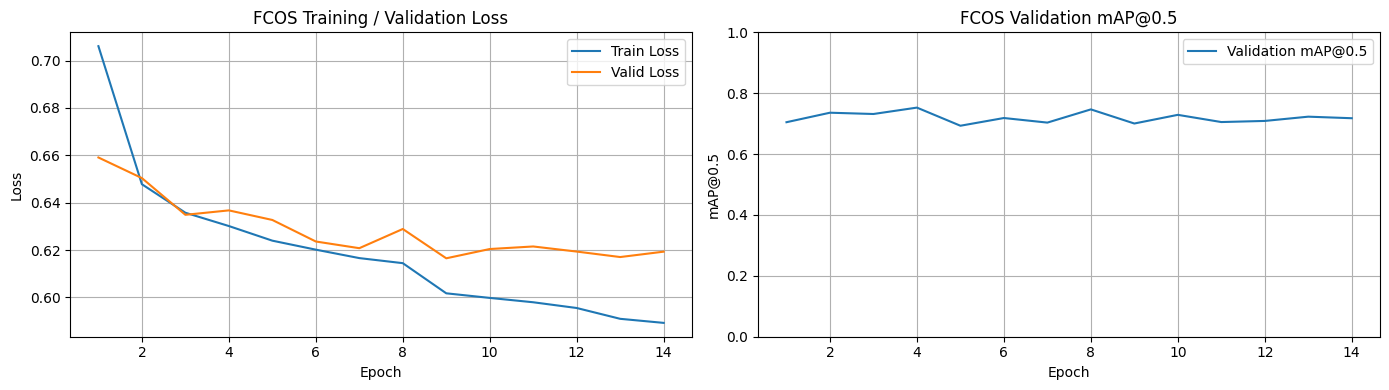

In [8]:
history_df = pd.DataFrame(history)
display(history_df.tail(10))

if len(history_df):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train Loss")
    axes[0].plot(history_df["epoch"], history_df["valid_loss"], label="Valid Loss")
    axes[0].set_title("FCOS Training / Validation Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[0].legend(); axes[0].grid(True)

    axes[1].plot(history_df["epoch"], history_df["valid_mAP50"], label="Validation mAP@0.5")
    axes[1].set_title("FCOS Validation mAP@0.5")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("mAP@0.5")
    axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].grid(True)
    plt.tight_layout()
    plt.show()

## 9. Muat checkpoint terbaik dan evaluasi akhir pada validation set

Checkpoint terbaik dimuat ulang untuk memastikan artefak final yang disimpan adalah model dengan validation mAP@0.5 terbaik, bukan bobot epoch terakhir.

In [9]:
if not os.path.isfile(BEST_PATH):
    raise FileNotFoundError(
        "fcos_best.pth belum terbentuk. Pastikan training berjalan minimal satu epoch."
    )

best_ckpt = torch.load(BEST_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(best_ckpt["model_state_dict"])
model.eval()

final_metrics = evaluate_map(model, valid_loader)
print("Best epoch:", best_ckpt["epoch"])
print("Best validation mAP@0.5:", best_ckpt["best_map"])
display(pd.DataFrame([
    {"Metric": "mAP@0.5", "Value": final_metrics["mAP@0.5"]},
    {"Metric": "Precision@0.5", "Value": final_metrics["Precision@0.5"]},
    {"Metric": "Recall@0.5", "Value": final_metrics["Recall@0.5"]},
    {"Metric": "TP@0.5", "Value": final_metrics["TP@0.5"]},
    {"Metric": "FP@0.5", "Value": final_metrics["FP@0.5"]},
    {"Metric": "FN@0.5", "Value": final_metrics["FN@0.5"]},
]))
display(pd.DataFrame(final_metrics["per_class"]).T)

Best epoch: 4
Best validation mAP@0.5: 0.7527012499101213


,Metric,Value
0,mAP@0.5,0.752701
1,Precision@0.5,0.788345
2,Recall@0.5,0.819429
3,TP@0.5,1434.000000
4,FP@0.5,385.000000
5,FN@0.5,316.000000


,AP50,GT,Precision@0.5,Recall@0.5
awake,0.801552,875.0,0.849941,0.828571
drowsy,0.703850,875.0,0.733954,0.810286


## 10. Ekspor artefak final

File output utama:
- `fcos_best.pth` — checkpoint model dengan validation mAP@0.5 terbaik.
- `fcos_last.pth` — checkpoint epoch terakhir, termasuk optimizer/scheduler/scaler untuk resume.
- `fcos_training_log.csv/json` — loss, mAP, precision, recall, waktu per epoch.
- `fcos_final_validation_metrics.json` — metrik validasi akhir dan metadata eksperimen.

Unduh folder `/kaggle/working/fcos_training_outputs` melalui panel Output Kaggle atau simpan sebagai Kaggle Dataset agar dapat dipakai notebook berikutnya.

In [10]:
final_report = {
    "model": "FCOS ResNet50 FPN",
    "num_classes_including_background": 3,
    "class_mapping": {"0": "background", "1": "awake", "2": "drowsy"},
    "best_epoch": int(best_ckpt["epoch"]),
    "best_valid_mAP50": float(best_ckpt["best_map"]),
    "final_validation_metrics": final_metrics,
    "setup_version": SETUP_VERSION,
    "cfg_hash": CFG_HASH,
    "seed": CFG["SEED"],
    "gpu": GPU_NAME,
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cfg": CFG,
}
with open(os.path.join(CFG["OUTPUT_DIR"], "fcos_final_validation_metrics.json"), "w") as f:
    json.dump(final_report, f, indent=2)

print("OUTPUT FILES")
for p in sorted(Path(CFG["OUTPUT_DIR"]).glob("*")):
    print(p.name, f"({p.stat().st_size/1024/1024:.2f} MB)")

OUTPUT FILES
fcos_best.pth (365.88 MB)
fcos_final_validation_metrics.json (0.00 MB)
fcos_last.pth (365.88 MB)
fcos_training_log.csv (0.00 MB)
fcos_training_log.json (0.00 MB)


## 11. Catatan operasional Kaggle

1. Tambahkan dataset penelitian melalui **Add Input**, lalu ubah `DATASET_ROOT`.
2. Aktifkan GPU T4 dan Internet pada Notebook Settings.
3. Jalankan sel dari atas. Bobot pretrained Torchvision akan diunduh pada eksekusi pertama.
4. Jika CUDA Out Of Memory: ubah `MICRO_BATCH_SIZE=4` dan `GRAD_ACCUM_STEPS=2`; `BATCH_SIZE` tetap 8.
5. Untuk resume pada sesi berikutnya, tambahkan output checkpoint sebagai Input Kaggle dan isi `RESUME_CHECKPOINT` dengan path `fcos_last.pth`.
6. Pastikan versi setup dan hash konfigurasi dicatat. Blok setup, preprocessing, seed, dan hyperparameter harus diselaraskan dengan notebook 01b RetinaNet agar komparasi adil.
7. Waktu training aktual bergantung pada GPU dan kompleksitas anotasi. Periksa waktu 50 iterasi pertama sebelum memperkirakan durasi keseluruhan.